# **ISOM4030 Lab 8 - Convolutional Neural Network (CNN) Part 2**



## Part 2: Transfer Learning and Data Augmentation for Image Classification

In the lecture, we covered two ideas that help when the labelled dataset is **small**:

- **Data augmentation**: create new, realistic training examples by applying random transformations, such as flips and rotations, to the images we already have. This reduces overfitting.
- **Transfer learning**: reuse a CNN pretrained on a large dataset (ImageNet) as a feature extractor. We **replace the last classification layer** with a new one for our own classes, **freeze** the pretrained layers, and train only the new layer. We can then **fine-tune** the top layers with a small learning rate.

In this task, you will apply both ideas to classify photos of **cats and dogs** with an ImageNet-pretrained **MobileNetV2**. Most of the code is provided: you only need to complete the cells marked **TODO** and answer the **Reflection Questions**.

## Step 0: Setup

In [1]:
import os, pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from tensorflow.keras import Sequential, layers, Input, applications

tf.keras.utils.set_random_seed(42)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load the data

The dataset has 2,000 training images and 1,000 validation images of cats and dogs, which is a **small** dataset for training a CNN.

In [2]:
# Download cats_and_dogs_filtered.zip from the course Google Drive and unzip it into /content.
# The gdown command below works in Colab.
# To download the data file to your own computer instead, use this link:
# https://drive.usercontent.google.com/download?id=1i9patiYa4RJJW-Ltby8eVvfkLItFv4ue

!gdown 1i9patiYa4RJJW-Ltby8eVvfkLItFv4ue -O /content/cats_and_dogs.zip -q
!unzip -q -o /content/cats_and_dogs.zip -d /content

PATH = pathlib.Path('/content/cats_and_dogs_filtered')
print(f"Downloaded and extracted to: {PATH}")

Downloaded and extracted to: /content/cats_and_dogs_filtered


After unzipping, the data is in `/content/cats_and_dogs_filtered`:

    cats_and_dogs_filtered/
    ├── train/
    │   ├── cats/   1,000 cat photos
    │   └── dogs/   1,000 dog photos
    └── validation/
        ├── cats/   500 cat photos
        └── dogs/   500 dog photos

- The top level splits the data into a **training** set (2,000 images) and a **validation** set (1,000 images). Both sets are balanced, with equal numbers of cats and dogs.
- Inside each split, there is **one subfolder per class**. There is no separate label file: **the folder an image is in tells you its label.**

The cell below loads the training images in batches of 32, resizing each image to 160 × 160.

Because the dataset has no separate test set, we hold out about 20% of the validation images as a test set and keep the remaining 80% for validation. The validation and test sets are also organized into batches of 32.

In [3]:
train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')

BATCH_SIZE = 32

# Resize every image to 160 x 160 as it is loaded
IMG_SIZE = (160, 160)

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir, shuffle=True, batch_size=BATCH_SIZE, image_size=IMG_SIZE)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir, shuffle=False, batch_size=BATCH_SIZE, image_size=IMG_SIZE)

validation_dataset = validation_dataset.unbatch().shuffle(
    1000, seed=42, reshuffle_each_iteration=False).batch(BATCH_SIZE)

class_names = train_dataset.class_names
print(class_names)

val_batches = 1000 // BATCH_SIZE + 1
test_dataset = validation_dataset.take(val_batches // 5)
validation_dataset = validation_dataset.skip(val_batches // 5)

print('\nTraining batches:', len(list(train_dataset)))
print('Validation batches:', len(list(validation_dataset)))
print('Test batches:', len(list(test_dataset)))

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
['cats', 'dogs']

Training batches: 63
Validation batches: 26
Test batches: 6


Run the cell below to view nine images from the first training batch, with their labels:

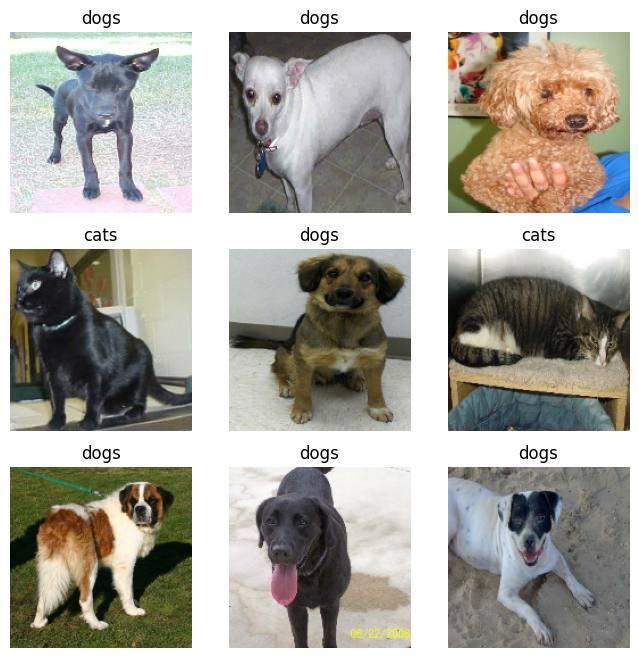

In [4]:
plt.figure(figsize=(8, 8))
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

## Step 2: Data augmentation

With only about 2,000 training images, a large CNN would easily overfit.

A good remedy is to increase the variety of the training data artificially, by applying random but realistic transformations to the training images, such as rotations and horizontal flips. This exposes the model to more varied views of the data and helps reduce overfitting.

The augmentation pipeline transforms each training image randomly **every time it is used**. The model never sees exactly the same image twice, yet every image still clearly shows a cat or a dog.

**TODO:** Complete `data_augmentation`, a `Sequential` pipeline made of two random transformations:

1. a random **horizontal** flip;
2. a random rotation of up to **±20% of a full turn** (about ±72°).

**Hints:**
- Keras provides augmentations as layers: `layers.RandomFlip(mode)` and `layers.RandomRotation(factor)`.
- For `RandomFlip`, `mode` is a string: `'horizontal'`, `'vertical'` or `'horizontal_and_vertical'`.
- For `RandomRotation`, `factor` is a fraction of a full circle (2π): `factor=0.2` means a random angle in [−20%, +20%] × 2π.
- These layers are active only during training (`model.fit`). They have no effect during `evaluate` and `predict`.

In [5]:
data_augmentation = Sequential([
    # TODO: add a layer that randomly flips images horizontally
    layers.RandomFlip("horizontal"),
    # TODO: add a layer that randomly rotates images by up to 20% of a full turn
    layers.RandomRotation(0.2),
])

Run the cell below to apply your pipeline 9 times to the **same** image. Each result should look different.

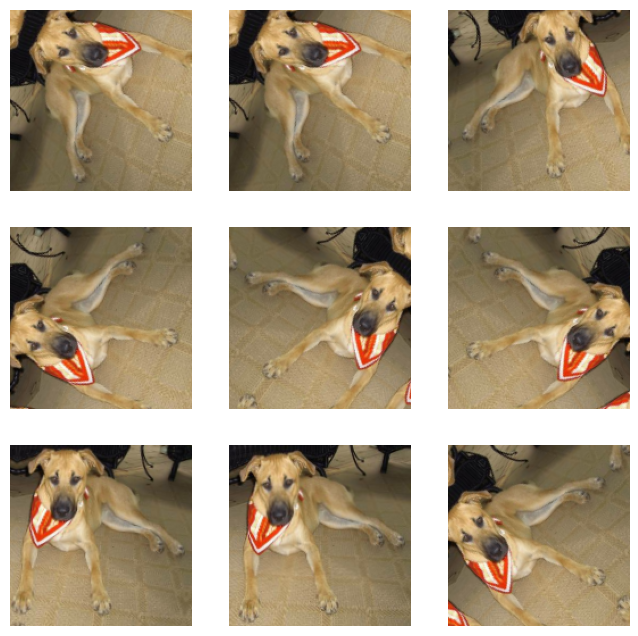

In [6]:
for image, _ in train_dataset.take(1):
    plt.figure(figsize=(8, 8))
    first_image = image[0]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented_image = data_augmentation(tf.expand_dims(first_image, 0), training=True)
        plt.imshow(augmented_image[0] / 255)
        plt.axis('off')

## Reflection Question 2.1

(a) In your own words, explain how data augmentation helps reduce overfitting.

(b) A vertical flip would also be easy to add. Would it be a sensible augmentation for cat and dog photos? Why or why not?

**Answer:**

_Write your answer here (1–3 sentences)._

---

## Step 3: Load a pretrained CNN without its classifier

MobileNetV2 expects pixel values in `[−1, 1]`, but our images are in `[0, 255]`. The model comes with its own preprocessing function to convert them:

In [7]:
preprocess_input = applications.mobilenet_v2.preprocess_input

Recall the lecture example: to reuse a VGG network trained on ImageNet's **1,000 classes** for **10 dog breeds**, we **removed the last fully connected layer** and added a new one of the right size.

Here we do the same with MobileNetV2. Keras can load the pretrained network **without** its ImageNet classification layers (the "top").

**TODO:** Load MobileNetV2 so that:
- it uses weights pretrained on ImageNet;
- its top (classification) layers are **not** included;
- it accepts 160 × 160 × 3 images.

**Hints:**
- `applications.MobileNetV2(input_shape=..., include_top=..., weights='imagenet')`
- `include_top` is a Boolean.
- `IMG_SIZE + (3,)` gives the shape `(160, 160, 3)`.

In [8]:
# TODO: fill in the two missing arguments
# (weights='imagenet' loads the weights pretrained on ImageNet)

base_model = applications.MobileNetV2(input_shape = IMG_SIZE + (3,),
                                      include_top = False,
                                      weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


The base turns each 160 × 160 × 3 image into a block of feature maps.

Run the cell below to check the output shape. You should see `(32, 5, 5, 1280)`.

In [9]:
image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(preprocess_input(image_batch))
print(feature_batch.shape)

(32, 5, 5, 1280)


In other words, the base outputs a 5 × 5 × 1280 block of features for each image.

Note: the first dimension is the batch size (32).

## Reflection Question 2.2

Why do we set `include_top=False` instead of keeping MobileNetV2's original classification layers?

**Answer:**

_Write your answer here (1–3 sentences)._

## Step 4: Freeze the pretrained layers

Next, we use the base as a fixed **feature extractor**: its weights must **not** change while we train the new classifier.

Every Keras layer and model has a Boolean attribute, `trainable`. Setting it on a model applies it to all of the model's layers.

In [10]:
base_model.trainable = False
print("Trainable weights in base:", len(base_model.trainable_weights))
print("Total parameters in base:", base_model.count_params())

Trainable weights in base: 0
Total parameters in base: 2257984


## Reflection Question 2.3

Our dataset has only 2,000 training images, while the base has over 2 million parameters. Why is freezing the base a good idea here?

**Answer:**

_Write your answer here (1–3 sentences)._

## Step 5: Add a new classification head and build the model

The base outputs a 5 × 5 × 1280 block of features for each image. To turn it into a single cat/dog prediction:

1. [`GlobalAveragePooling2D`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GlobalAveragePooling2D) averages each of the 1,280 feature maps over its 5 × 5 positions, giving a **1,280-dimensional vector**.
2. A `Dense` layer with **one unit** produces a single raw score (a *logit*): positive means "dog" (class 1) and negative means "cat" (class 0). We leave out the activation function, because the loss applies the sigmoid itself (`from_logits=True`).

**TODO (a):** Create the two head layers.

**Hints:** `layers.GlobalAveragePooling2D()` and `layers.Dense(units)`.

In [11]:
# TODO: global average pooling layer
global_average_layer = layers.GlobalAveragePooling2D()
# TODO: a Dense layer with 1 output unit and no activation
prediction_layer = layers.Dense(1)

In [12]:
print(global_average_layer(feature_batch).shape)
print(prediction_layer(global_average_layer(feature_batch)).shape)

(32, 1280)
(32, 1)


**TODO (b):** Chain all the pieces together with the Keras functional API, in this order:

`inputs → data augmentation → preprocessing → pretrained base → global average pooling → dropout → prediction layer`

**Hints:**
- Start with `Input(shape=...)`. Each example is a 160 × 160 × 3 image, so you can reuse `IMG_SIZE + (3,)`.
- In the functional API, each layer is *called* on the previous tensor: `x = layer(x)`.
- Call the base as `base_model(x, training=False)`. This keeps its BatchNormalization layers in inference mode, so they keep using the statistics learned on ImageNet. This matters again when we fine-tune in Step 7.
- The dropout line is given.

In [13]:
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))     # TODO: specify the shape of each input example
x = data_augmentation(inputs)                      # TODO: apply data augmentation to inputs
x = preprocess_input(x)                            # TODO: apply preprocess_input defined in step 3
x = base_model(x, training=False)                  # TODO: apply base_model (remember training=False)
x = global_average_layer(x)                        # TODO: apply global average pooling
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)                      # TODO: apply the prediction layer
model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Reflection Question 2.4

`model.summary()` reports only **1,281** trainable parameters, even though the whole model has more than 2 million.

(a) Show where the number 1,281 comes from.

(b) Why is having so few trainable parameters an advantage with a small dataset?

**Answer:**

_Write your answer here (1–3 sentences)._

## Step 6: Compile and train

In [14]:
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0, name='accuracy')])

initial_epochs = 10
loss0, accuracy0 = model.evaluate(validation_dataset)
print("Accuracy before training: {:.2f}".format(accuracy0))

history = model.fit(train_dataset,
                    epochs=initial_epochs,
                    validation_data=validation_dataset)

26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3168 - loss: 0.9728
Accuracy before training: 0.32
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.5070 - loss: 0.8089 - val_accuracy: 0.6225 - val_loss: 0.6495
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.6935 - loss: 0.5968 - val_accuracy: 0.8428 - val_loss: 0.4564
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.8020 - loss: 0.4624 - val_accuracy: 0.9097 - val_loss: 0.3446
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8365 - loss: 0.3876 - val_accuracy: 0.9369 - val_loss: 0.2749
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8725 - loss: 0.3344 - val_accuracy: 0.9517 - val_loss: 0.2287
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.8930 - loss: 0.2930 - val_accuracy: 0.9579 - val_loss: 0.1977
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.8970 - loss: 0.2730 - val_accuracy: 0.9604 - val_loss: 0.1743
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9020 - loss: 0.2503 - val_accuracy: 0.9629 - val_loss: 0

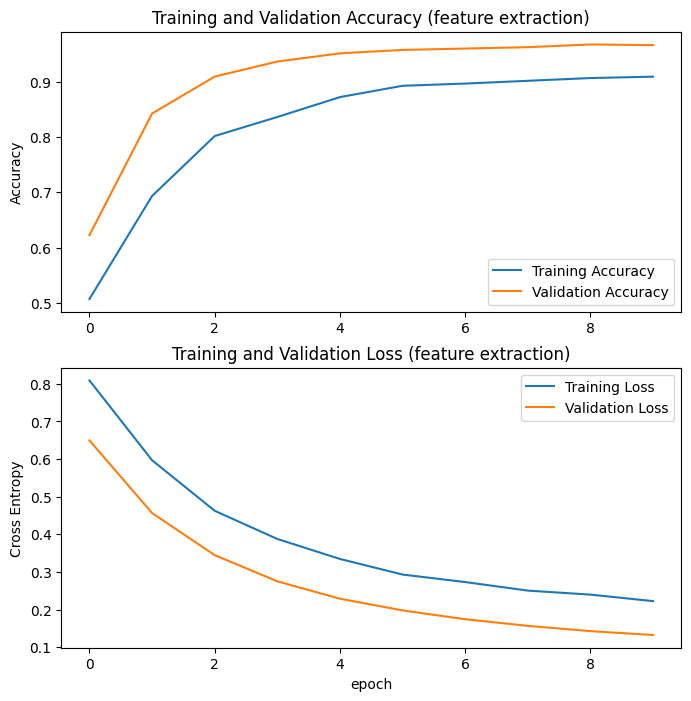

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9635 - loss: 0.1391
Test accuracy after feature extraction: 0.9635


In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right'); plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy (feature extraction)')
plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right'); plt.ylabel('Cross Entropy'); plt.xlabel('epoch')
plt.title('Training and Validation Loss (feature extraction)')
plt.show()

fe_loss, fe_accuracy = model.evaluate(test_dataset)
print('Test accuracy after feature extraction: {:.4f}'.format(fe_accuracy))

## Step 7: Fine-tune the top layers

Now that the new head is trained, we can go one step further.

We **unfreeze the top layers** of the base and train them together with the head, using a **much smaller learning rate**: here, **10 times smaller** than `base_learning_rate`.

This adapts the most task-specific (high-level) features to cats and dogs, while the generic low-level features in the early layers stay frozen.

To do this, we first make the whole base trainable again. Then we re-freeze every layer **before** index `fine_tune_at` (layers 0 to 99), so that only layers 100 onwards are trained.

In [16]:
print("Number of layers in the base model:", len(base_model.layers))
fine_tune_at = 100

# Unfreeze the whole base model
base_model.trainable = True

# base_model.layers is a Python list,
# so base_model.layers[:fine_tune_at] gives the first fine_tune_at layers.
# Freeze each of these layers again, one by one.
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile so that the changes to `trainable` take effect
model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer=tf.keras.optimizers.RMSprop(learning_rate=base_learning_rate / 10),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0, name='accuracy')])
print("Trainable variables:", len(model.trainable_variables))

Number of layers in the base model: 154
Trainable variables: 56


## Step 8: Continue training

In [17]:
fine_tune_epochs = 10
total_epochs = initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         validation_data=validation_dataset)

Epoch 11/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - accuracy: 0.7840 - loss: 0.4312 - val_accuracy: 0.9777 - val_loss: 0.0954
Epoch 12/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step - accuracy: 0.8830 - loss: 0.2810 - val_accuracy: 0.9765 - val_loss: 0.0779
Epoch 13/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.9105 - loss: 0.2167 - val_accuracy: 0.9814 - val_loss: 0.0682
Epoch 14/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.9270 - loss: 0.1922 - val_accuracy: 0.9814 - val_loss: 0.0583
Epoch 15/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.9330 - loss: 0.1662 - val_accuracy: 0.9851 - val_loss: 0.0524
Epoch 16/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.9420 - loss: 0.1494 - val_accuracy: 0.9864 - val_loss: 0.0483
Epoch 17/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.9415 - loss: 0.1496 - val_accuracy: 0.9851 - val_loss: 0.0457
Epoch 18/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.9430 - loss: 0.1470 - val_accuracy: 

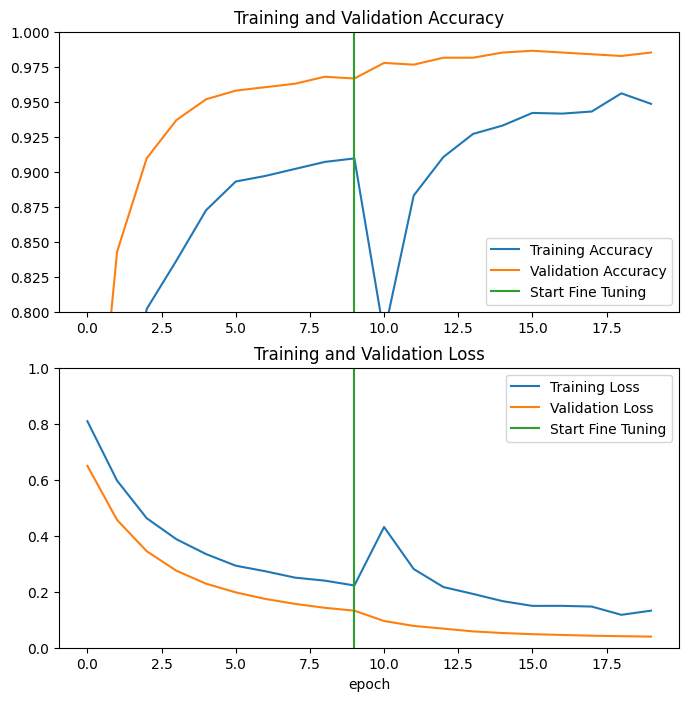

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9792 - loss: 0.0479
Test accuracy after feature extraction: 0.9635
Test accuracy after fine-tuning:        0.9792


In [18]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']
loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs - 1, initial_epochs - 1], plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right'); plt.title('Training and Validation Accuracy')
plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs - 1, initial_epochs - 1], plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right'); plt.title('Training and Validation Loss'); plt.xlabel('epoch')
plt.show()

ft_loss, ft_accuracy = model.evaluate(test_dataset)
print('Test accuracy after feature extraction: {:.4f}'.format(fe_accuracy))
print('Test accuracy after fine-tuning:        {:.4f}'.format(ft_accuracy))

## Reflection Question 2.5

(a) Why do we fine-tune only the **top** layers rather than the whole network? (Hint: think about what early and deep CNN layers learn.)

(b) Why must the learning rate be much smaller during fine-tuning?

**Answer:**

_Write your answer here (1–3 sentences)._

## Step 9: View the predictions

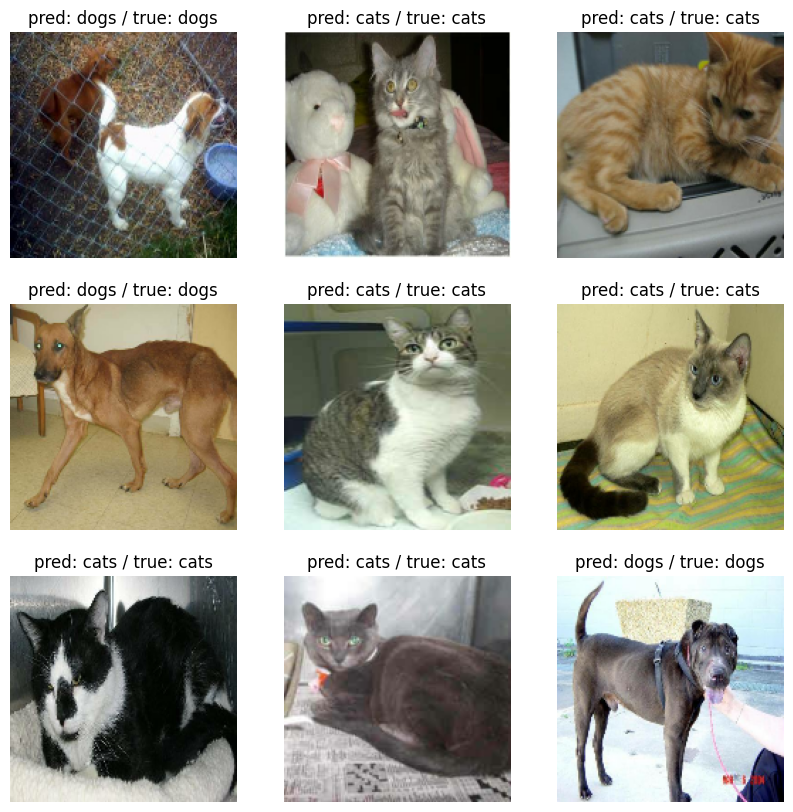

In [19]:
image_batch, label_batch = test_dataset.as_numpy_iterator().next()
predictions = model.predict_on_batch(image_batch).flatten()
predictions = tf.where(tf.nn.sigmoid(predictions) < 0.5, 0, 1)   # logits -> probabilities -> labels

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(f"pred: {class_names[predictions[i]]} / true: {class_names[label_batch[i]]}")
    plt.axis("off")

## Reflection Question 2.6

Compare the test accuracy after feature extraction with the test accuracy after fine-tuning. Use your own learning curves to answer:

(a) Did fine-tuning help, and by roughly how much?

(b) Do you see any signs of overfitting after fine-tuning starts? (Look at the gap between the training and validation loss.)

**Answer:**

_Write your answer here (1–3 sentences)._